In [1]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from matplotlib import cm
from datetime import date
import re
from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, fisher_exact, describe, hypergeom
from scipy.spatial.distance import jaccard, euclidean, cosine, pdist, squareform
import functools
import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from scipy.cluster import hierarchy
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
from collections import Counter
# from region_comparison_combine_scores_CT20220810 import combine_scores
from operator import is_not

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    return fig

**Counts -> Sigmoid scale**

In [113]:
count_path='/home/ctrader/region_similarity/data/count_based/regions_25kb_CT20221025.DHScounts.hdf5'

In [115]:
#load the data
count_hdf5 = h5py.File(count_path, 'r')
count_arr = count_hdf5['base_arr'][:]
count_hdf5.close()

In [116]:
dhs = []
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220815.DHSmapped.bed', 'r')
comp_names = f.readline().strip().split('\t')[3:]
f.close()

Text(-0.02, 0.48, 'Region Count')

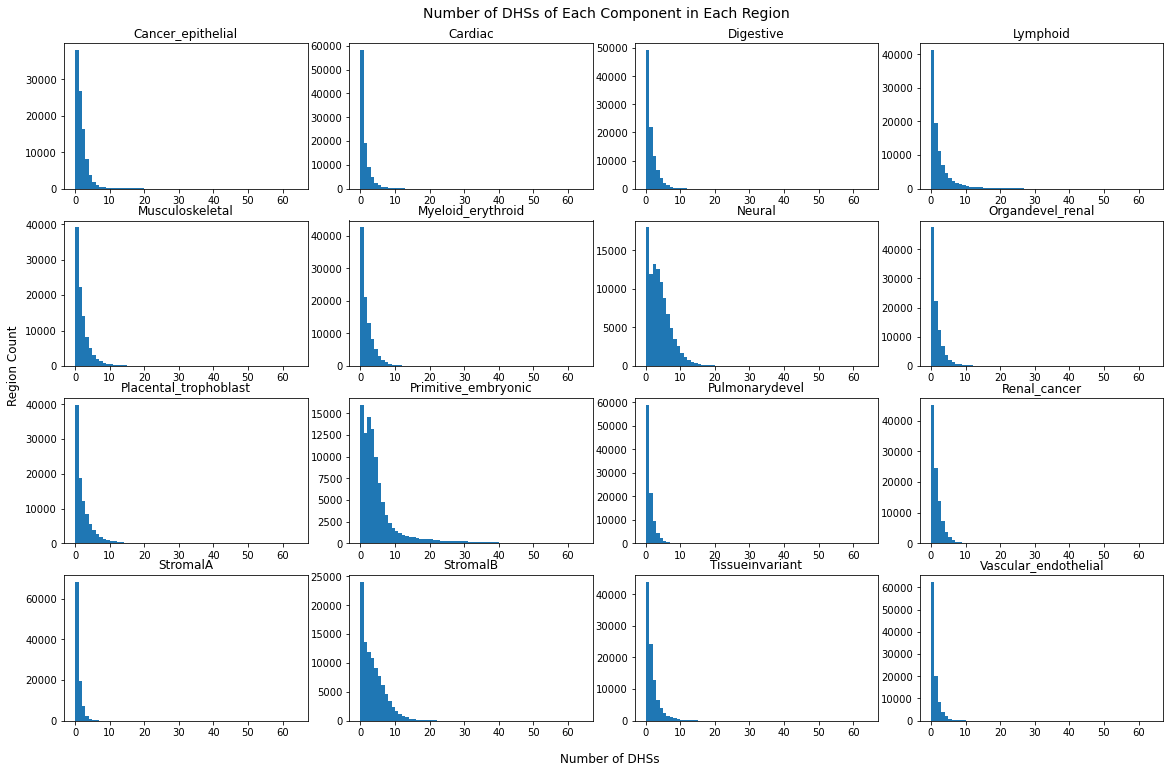

In [6]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16, 10))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()

max_count = np.max(count_arr)

for i, ax, comp in zip(range(16), axes, comp_names):
    ax.hist(count_arr[:, i], bins=np.arange(max_count+1))
    ax.set_title(comp)
    
fig.suptitle('Number of DHSs of Each Component in Each Region', y=1.03, fontsize=14)
fig.text(0.46, -0.02, 'Number of DHSs', fontsize=12)
fig.text(-0.02, 0.48, 'Region Count', fontsize=12, rotation=90)

In [124]:
#rank each region based on counts
ranked_counts = rankdata(count_arr, axis=0)

In [125]:
ranked_counts

array([[18990. , 29086.5, 24618.5, ..., 12000. , 21939. , 31214. ],
       [18990. , 29086.5, 24618.5, ..., 12000. , 21939. , 31214. ],
       [18990. , 29086.5, 24618.5, ..., 30828.5, 21939. , 31214. ],
       ...,
       [18990. , 29086.5, 24618.5, ..., 12000. , 21939. , 31214. ],
       [18990. , 29086.5, 24618.5, ..., 12000. , 21939. , 31214. ],
       [18990. , 29086.5, 24618.5, ..., 12000. , 21939. , 31214. ]])

In [127]:
#limit component ranks to just ragions with at least 1 DHS of that component
ranked_counts = np.where(count_arr==0, 0, ranked_counts)

In [121]:
ranked_counts

array([[    0. ,     0. ,     0. , ...,     0. ,     0. ,     0. ],
       [    0. ,     0. ,     0. , ...,     0. ,     0. ,     0. ],
       [    0. ,     0. ,     0. , ..., 30828.5,     0. ,     0. ],
       ...,
       [    0. ,     0. ,     0. , ...,     0. ,     0. ,     0. ],
       [    0. ,     0. ,     0. , ...,     0. ,     0. ,     0. ],
       [    0. ,     0. ,     0. , ...,     0. ,     0. ,     0. ]])

In [122]:
ranked_counts.shape

(98629, 16)

In [123]:
np.count_nonzero(ranked_counts)/16

55362.5

Text(0.5, 1.0, 'Comparing Scaling Factors for Sigmoid Function')

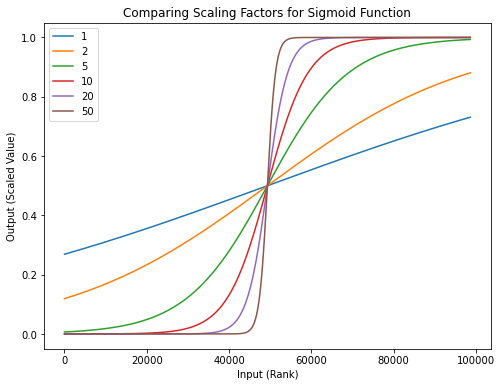

In [72]:
def sigmoid_func(arr, scaling_factor=5):
    num_regions = len(arr)
    x = (arr / (num_regions / (scaling_factor * 2))) - scaling_factor
    sig_arr = 1 / (1 + np.exp(-x))
    return sig_arr

fig = plt.figure(figsize=(8, 6))
fig.patch.set_facecolor('white')

sf = [1, 2, 5, 10, 20, 50]
for i in sf:
    t = sigmoid_func(np.arange(len(ranked_counts)), scaling_factor=i)
    plt.plot(t)

plt.legend(sf)
plt.xlabel('Input (Rank)')
plt.ylabel('Output (Scaled Value)')
plt.title('Comparing Scaling Factors for Sigmoid Function')

In [10]:
#ordering DHS colors
DHS_comps_paper = np.array(['Placental / trophoblast', 'Lymphoid', 'Myeloid / erythroid', 'Cardiac', 
                            'Musculoskeletal', 'Vascular / endothelial', 'Primitive / embryonic', 
                            'Neural', 'Digestive', 'Stromal A', 'Stromal B', 'Renal / cancer', 
                            'Cancer / epithelial', 'Pulmonary devel.', 'Organ devel. / renal', 
                            'Tissue invariant'])

DHS_color = np.array(['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', 
                      '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3'])

DHS_color = DHS_color[np.argsort(DHS_comps_paper)]

Text(0.5, 1.0, 'Sigmoid Values for Regional DHS Ranks')

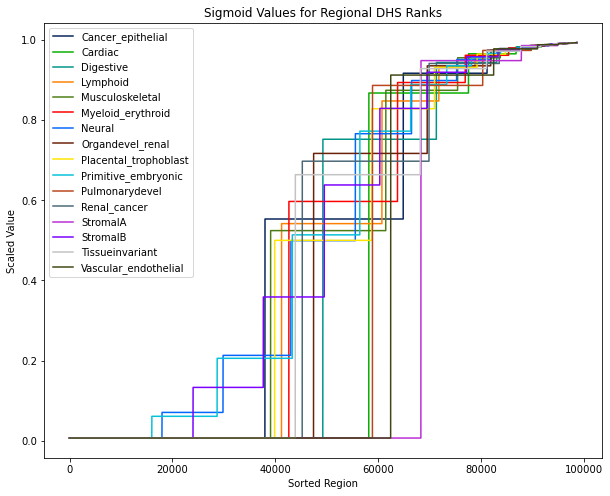

In [128]:
fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')


for i, comp, c in zip(range(16), comp_names, DHS_color):
    t = sigmoid_func(np.sort(ranked_counts[:, i]))
    plt.plot(t, color=c)

plt.legend(comp_names)
plt.ylabel('Scaled Value')
plt.xlabel('Sorted Region')
plt.title('Sigmoid Values for Regional DHS Ranks')

In [12]:
#sigmoid of rank for all regions
sigmoid_ranks = sigmoid_func(ranked_counts)

**Euclidean Distance**

In [13]:
#euclidean distance matrix
distance_m = squareform(pdist(sigmoid_ranks[:10000], metric='euclidean'))

In [14]:
#find the max distance
max_distance = np.max(distance_m)

In [15]:
#sim matrix
sim_m = max_distance - distance_m

In [16]:
#regions with 0 DHSs
dhs_per_region = np.sum(count_arr, axis=1)
regions_0_DHSs = np.where(dhs_per_region==0)[0]

#for now...
regions_0_DHSs = regions_0_DHSs[regions_0_DHSs<10000]

In [17]:
#setting similarity values in regions with no DHSs to 0
sim_m[regions_0_DHSs] = 0
sim_m[:, regions_0_DHSs] = 0

In [18]:
max_distance

3.8158296747427056

In [19]:
np.max(sim_m)

3.8158296747427056

In [22]:
#top 1000 regions and values
def find_top_regions(sim_m):
    top_regions_all = []
    top_vals_all = []
    for i in range(len(sim_m)):
        top_regions = np.argsort(-sim_m[i])[:1001]
        top_regions = top_regions[top_regions!=i][:1000]
        top_regions_all.append(top_regions)
        top_vals_all.append(sim_m[i, top_regions])
    top_regions_all = np.array(top_regions_all)
    top_vals_all = np.array(top_vals_all)
    return top_regions_all, top_vals_all
top_regions_all, top_vals_all = find_top_regions(sim_m)

In [65]:
np.argsort(-distance_m[i])

array([7767, 7037,  338, ..., 1700, 6879, 9999])

In [29]:
def scale_data(data, max_poss):
    data_to_rank = data[data!=0]
    max_obs = np.max(data_to_rank)
    rank_data = rankdata(data_to_rank, method='average')
    rank_data = rank_data/(len(data_to_rank))
    rank_data = rank_data * max_obs/max_poss

    original_data_shape = data.shape
    data = data.astype(float).flatten()
    np.put(data, np.where(data!=0)[0], rank_data)
    data = data.reshape(original_data_shape)
    return data
top_scaled_vals = scale_data(top_vals_all, max_distance)

In [45]:
#load the data
sigmoideuc_path = '/home/ctrader/region_similarity/data/count_based/regions_25kb_CT20221025.DHSsigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
top_1000_scaled_vals = sigmoideuc_hdf5['top_1000_scaled_vals'][:]
top_1000_similar_regions = sigmoideuc_hdf5['top_1000_similar_regions'][:]
top_1000_sigmoideuc_vals = sigmoideuc_hdf5['top_1000_sigmoideuc_vals'][:]
sigmoideuc_hdf5.close()

**Chromatin States**

In [129]:
count_path='/home/ctrader/region_similarity/data/count_based/regions_25kb_CT20221025.epilogosmeanmax.hdf5'
#load the data
count_hdf5 = h5py.File(count_path, 'r')
count_arr = count_hdf5['base_arr'][:]
count_hdf5.close()

In [130]:
#rank each region based on counts
ranked_counts = rankdata(count_arr, axis=0)

In [131]:
ranked_counts

array([[41080. , 41586. , 35884.5, ..., 39147.5, 36121. , 24416. ],
       [41080. , 41586. , 35884.5, ..., 39147.5, 36121. , 24416. ],
       [41080. , 32356.5, 35884.5, ..., 39147.5, 36121. , 24416. ],
       ...,
       [41080. , 41586. , 35884.5, ..., 39147.5, 36121. , 24416. ],
       [41080. , 41586. , 35884.5, ..., 39147.5, 36121. , 24416. ],
       [41080. , 41586. , 35884.5, ..., 39147.5, 36121. , 24416. ]])

Text(0.5, 1.0, 'Sigmoid Values for Regional CS Ranks')

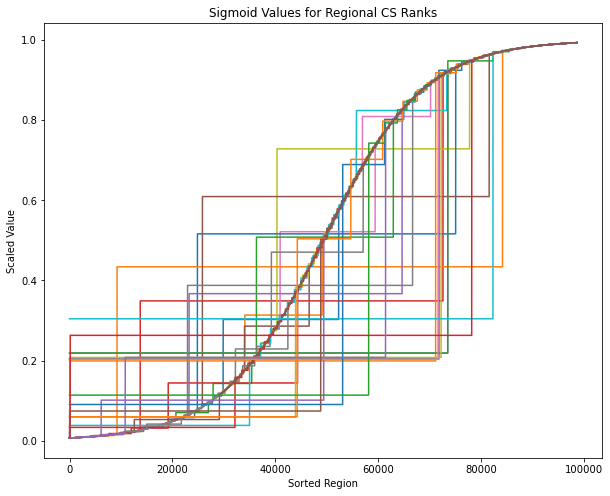

In [135]:
fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')


for i in range(36):
    t = sigmoid_func(np.sort(ranked_counts[:, i]))
    plt.plot(t)

plt.ylabel('Scaled Value')
plt.xlabel('Sorted Region')
plt.title('Sigmoid Values for Regional CS Ranks')

In [136]:
#sigmoid of rank for all regions
sigmoid_ranks = sigmoid_func(ranked_counts)

In [137]:
#euclidean distance matrix
distance_m = squareform(pdist(sigmoid_ranks[:10000], metric='euclidean'))

In [138]:
#find the max distance
max_distance = np.max(distance_m)

In [139]:
max_distance

5.330072559839385

In [140]:
#sim matrix
sim_m = max_distance - distance_m

In [153]:
count_arr[4796]

array([ 0.,  0., -0.,  0., -0.,  0.,  0., -0., -0.,  0., -0., -0., -0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.])

In [149]:
top_regions_all, top_vals_all = find_top_regions(sim_m)

**STRING**